In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# Chemin vers le dataset
DATA_DIR = Path("../Data")

# Les 4 classes
CLASSES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())

Dataset path: C:\Users\ajbba\Desktop\YOUCODE-IA\BrainScan\Data
Dataset exists: True


In [2]:

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

records = []

for class_name in CLASSES:
    class_dir = DATA_DIR / class_name

    for image_path in class_dir.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "image_path": str(image_path),
                "class": class_name
            })

df = pd.DataFrame(records)

print("Nombre total d'images :", len(df))
print("\nNombre d'images par classe :")
print(df["class"].value_counts())

df.head()

Nombre total d'images : 7023

Nombre d'images par classe :
class
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64


,image_path,class
0,..\Data\glioma\Te-glTr_0000.jpg,glioma
1,..\Data\glioma\Te-glTr_0001.jpg,glioma
2,..\Data\glioma\Te-glTr_0002.jpg,glioma
3,..\Data\glioma\Te-glTr_0003.jpg,glioma
4,..\Data\glioma\Te-glTr_0004.jpg,glioma


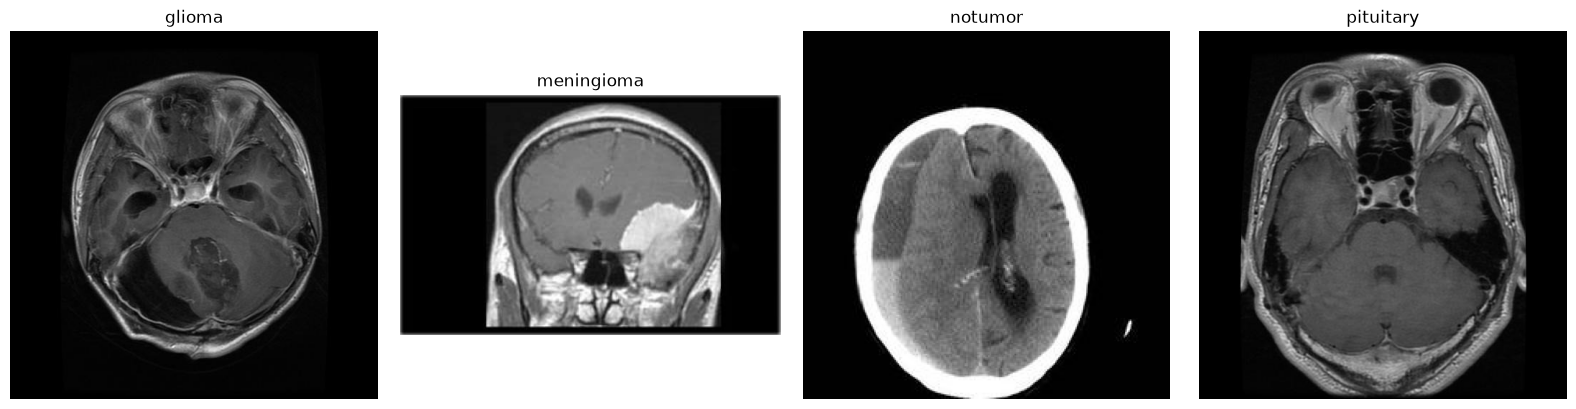

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, class_name in zip(axes, CLASSES):
    image_path = df.loc[df["class"] == class_name, "image_path"].iloc[0]

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()